> **Executed record of a Kaggle kernel.** The cells below are the cells that ran. Kaggle does not return the executed notebook, so the outputs were put back afterwards by `tools/attach_kaggle_outputs.py`: printed text comes from the kernel's log (each line assigned to the cell whose code prints it), and each table or figure comes from the CSV or PNG file that cell saved. Everything shown was produced by the run; the placement is a reconstruction. Kernel: `dr-s6-train`.

> **Kaggle kernel `dr-s6-train`.** The 4 training runs (blur-aware sigma x 3 seeds, shuffled control x 1) and the analysis. Built by `experiments/08_blur_aware/kaggle/build_kernels.py` from `experiments/08_blur_aware/08_blur_aware.ipynb`; only the Drive setup and the QUICK_TEST switch differ.

# Stage 6: Blur-Aware Soft Labels for Diabetic Retinopathy Grading
### Does a wider soft label for blurrier training images lower the error rate on blurry test images?

**Hypothesis (M3, written before this notebook was run):** [`experiments/08_blur_aware/hypothesis.md`](hypothesis.md). Stage 4 found that misgraded images are blurrier. Here each training image gets its own soft-label width sigma_i = 0.7 - 0.4 r_i, where r_i is its sharpness rank among the training images (0 = blurriest, 1 = sharpest). The average width stays 0.5, the same as Stage 5.

**Baseline (not retrained):** the three Stage 5 soft-label runs (`soft_s42/43/44`, fixed sigma 0.5), read from the `dr-s5-train` kernel output.

| Run | sigma per image | Question |
|---|---|---|
| `blur_s42/43/44` | 0.7 - 0.4 r_i (blurrier = wider) | **the hypothesis** |
| `blur_shuffled_s42` | the same values, assigned to images at random | is it blur, or just *varying* sigma? |

Arms (same two decision rules as Stage 5): **G** = majority vote, **H** = expected grade with validation-tuned cut-offs. Settings: QUICK_TEST in section 1; Kaggle inputs: kernel `dr-s5-train`.

## 1. Setup and settings

Every hyper-parameter lives in one `Config`. The defaults are the Stage 3 baseline; an experiment changes only `loss` (`"ce"` or `"mse"`), `seed` and `dedupe`.

In [1]:
import hashlib
import io
import json
import math
import os
import random
import subprocess
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, fields, replace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support, roc_auc_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

try:
    import timm
except ImportError:                      # not preinstalled on this machine
    !pip install -q timm
    import timm

CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Kaggle: results go to /kaggle/working (this kernel's output); images are downloaded to the local disk.
WORK_DIR = Path("/kaggle/working/dr-grading")
LOCAL_DIR = Path("/tmp/dr")
LOCAL_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU found (very slow!)")

device: cuda | Tesla T4


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


In [2]:
QUICK_TEST = False        # True = tiny run (few epochs, few batches, separate output folder) to check the pipeline
CHECKPOINT_EVERY = 1      # save a resumable checkpoint every N epochs
SPLIT_SEED = 42           # the train/val/test split is the same for every run (same as Stage 3)


@dataclass
class Config:
    # The Stage 3 baseline `2_aug_lr1e-4`: paper settings plus augmentation and lr 1e-4.
    image_size: int = 300
    epochs: int = 60
    batch_size: int = 16
    lr: float = 1e-4
    weight_decay: float = 1e-4
    grad_clip: float = 0.1
    n_snapshots: int = 10
    seed: int = 42                # training seed (weights init, batch order, augmentation); the split stays fixed
    backbone: str = "efficientnet_b3"
    pretrained: bool = True
    use_amp: bool = True
    augment: bool = True
    loss: str = "soft"            # "ce" = one-hot cross-entropy (Stage 3); "mse" = ordinal regression (Stage 4); "soft" = Gaussian soft labels (Stage 5)
    sigma: float = 0.5            # width of the Gaussian soft label, in grades (only for loss="soft")
    sigma_mode: str = "fixed"     # "fixed" = the same sigma for every image (Stage 5); "blur" = wider for blurrier images; "shuffled" = the blur values in random order (control)
    dedupe: bool = False          # True = drop conflicting duplicates and keep one copy of each identical image
    max_train_batches: int = 0    # 0 = all batches; >0 only for the quick test


BASE_CFG = Config()
SEEDS = [42, 43, 44]
STAGE6_DIR = WORK_DIR / "stage6"
if QUICK_TEST:
    BASE_CFG = replace(BASE_CFG, epochs=4, n_snapshots=2, max_train_batches=5, image_size=224)
    SEEDS = [42, 43]
    STAGE6_DIR = WORK_DIR / "stage6_quick_test"            # never mixed with the real runs
if device.type != "cuda" and not QUICK_TEST:
    raise RuntimeError("This runtime has no GPU (Colab falls back to CPU when the free GPU time runs out). "
                       "Runtime -> Change runtime type -> T4 GPU, then Run all again. On a CPU the settings would "
                       "not match the saved runs, and training would take days.")
if device.type != "cuda":
    BASE_CFG = replace(BASE_CFG, use_amp=False)             # mixed precision is a GPU feature
RUNS_DIR, FIG_DIR = STAGE6_DIR / "runs", STAGE6_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = {f"blur_s{seed}": replace(BASE_CFG, loss="soft", sigma_mode="blur", seed=seed) for seed in SEEDS}
EXPERIMENTS[f"blur_shuffled_s{SEEDS[0]}"] = replace(BASE_CFG, loss="soft", sigma_mode="shuffled", seed=SEEDS[0])      # control (R4)

print(json.dumps(asdict(BASE_CFG), indent=2))
print("experiments:", ", ".join(EXPERIMENTS))

{
  "image_size": 300,
  "epochs": 60,
  "batch_size": 16,
  "lr": 0.0001,
  "weight_decay": 0.0001,
  "grad_clip": 0.1,
  "n_snapshots": 10,
  "seed": 42,
  "backbone": "efficientnet_b3",
  "pretrained": true,
  "use_amp": true,
  "augment": true,
  "loss": "soft",
  "sigma": 0.5,
  "sigma_mode": "fixed",
  "dedupe": false,
  "max_train_batches": 0
}
experiments: blur_s42, blur_s43, blur_s44, blur_shuffled_s42


## 2. Data

APTOS 2019: 3,662 labelled fundus photographs, five grades. Same source and cache as Stage 3: the full-resolution Hugging Face mirror [`sngsfydy/aptos`](https://huggingface.co/datasets/sngsfydy/aptos), shrunk to 512 px on the long side, with a zipped copy on Drive. Because the image order comes from the same `labels.csv`, the split below is **identical to Stage 3**.

In [3]:
HF_REPO = "sngsfydy/aptos"
IMG_DIR = LOCAL_DIR / "aptos512"
DRIVE_CACHE = WORK_DIR / "aptos512.zip"
MAX_SIDE = 512


def list_shards():
    with urllib.request.urlopen(f"https://huggingface.co/api/datasets/{HF_REPO}/tree/main/data") as r:
        return sorted(f["path"] for f in json.load(r) if f["path"].endswith(".parquet"))


def convert_shard(parquet_path, out_dir):
    # Save every image in one parquet shard as a <hash>.jpg (<= 512 px). Returns [(file name, grade), ...].
    rows = []
    pf = pq.ParquetFile(parquet_path)
    for group in range(pf.num_row_groups):
        table = pf.read_row_group(group).to_pydict()
        for img, label in zip(table["image"], table["label"]):
            raw = img["bytes"]
            name = hashlib.sha1(raw).hexdigest()[:16] + ".jpg"     # identical photos get identical names
            im = Image.open(io.BytesIO(raw)).convert("RGB")
            scale = MAX_SIDE / max(im.size)
            im.resize((round(im.width * scale), round(im.height * scale)), Image.LANCZOS).save(out_dir / name, quality=95)
            rows.append((name, int(label)))
    return rows


def download_aptos(out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for shard in list_shards():
        local = LOCAL_DIR / Path(shard).name
        print("downloading", local.name, flush=True)
        subprocess.run(["curl", "-sSL", "--retry", "5", "-o", str(local),
                        f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{shard}"], check=True)
        rows += convert_shard(local, out_dir)
        local.unlink()                                             # free the disk before the next shard
        print(f"  {len(rows)} images so far", flush=True)
    pd.DataFrame(rows, columns=["id_code", "label"]).to_csv(out_dir / "labels.csv", index=False)


if not (IMG_DIR / "labels.csv").exists():
    if DRIVE_CACHE.exists():                                       # Stage 3 (or an earlier session) did the download
        print("restoring cached images from Drive ...")
        subprocess.run(["unzip", "-q", "-o", str(DRIVE_CACHE), "-d", str(IMG_DIR)], check=True)
    else:
        download_aptos(IMG_DIR)
        print("saving a cache to Drive for next time ...")
        pass

df = pd.read_csv(IMG_DIR / "labels.csv")
df["path"] = df["id_code"].map(lambda name: IMG_DIR / name)
labels = df["label"].to_numpy()
print(f"{len(df)} images, {df['id_code'].nunique()} distinct files")

downloading train-00000-of-00013-b6971806b485b32b.parquet
  282 images so far
downloading train-00001-of-00013-3ef9284bda48b8de.parquet
  564 images so far
downloading train-00002-of-00013-3007d5f3a80d01a9.parquet
  846 images so far
downloading train-00003-of-00013-719dc2a41d6066fd.parquet
  1128 images so far
downloading train-00004-of-00013-1f950a0df3320b4b.parquet
  1410 images so far
downloading train-00005-of-00013-c0ede249a4a1709b.parquet
  1692 images so far
downloading train-00006-of-00013-da6bef6a92e83c30.parquet
  1974 images so far
downloading train-00007-of-00013-4f07a72750e770a9.parquet
  2256 images so far
downloading train-00008-of-00013-f29fe432adc405e3.parquet
  2538 images so far
downloading train-00009-of-00013-8df8c03a53f6153a.parquet
  2819 images so far
downloading train-00010-of-00013-5ce8efdfff11f693.parquet
  3100 images so far
downloading train-00011-of-00013-dc0bde52a2716ecc.parquet
  3381 images so far
downloading train-00012-of-00013-2fde0e05e0019c87.parqu

### Duplicates and the two splits

APTOS contains byte-identical images, some with **conflicting grades**. The main experiments use the Stage 3 split (all images, stratified 70/15/15, seed 42). The de-duplication check (prediction P8) uses a second split built after **removing every image whose copies disagree** and **keeping one copy of each remaining identical group**, so no test image has a twin in training.

In [4]:
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


with ThreadPoolExecutor(os.cpu_count()) as pool:
    df["hash"] = list(tqdm(pool.map(file_hash, df["path"]), total=len(df), desc="hashing"))

groups = df.groupby("hash")["label"].agg(["size", "nunique"])
conflict_hashes = set(groups.index[groups["nunique"] > 1])
df["conflicting_duplicate"] = df["hash"].isin(conflict_hashes)
print(f"{int((groups['size'] > 1).sum())} groups of identical images, {len(conflict_hashes)} of them with conflicting grades")


def make_split(positions, seed=SPLIT_SEED, val_frac=0.15, test_frac=0.15):
    # Stratified train/val/test row positions (into df). With all positions this is exactly the Stage 3 split.
    train_val, test = train_test_split(positions, test_size=test_frac, stratify=labels[positions], random_state=seed)
    train, val = train_test_split(train_val, test_size=val_frac / (1 - test_frac),
                                  stratify=labels[train_val], random_state=seed)
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


keep = ~df["conflicting_duplicate"] & ~df.duplicated("hash")      # de-duplicated data set
SPLITS = {False: make_split(np.arange(len(df))), True: make_split(np.flatnonzero(keep.to_numpy()))}

for dedupe, split in SPLITS.items():
    train_hashes = set(df["hash"].to_numpy()[split["train"]])
    leaked = sum(h in train_hashes for h in df["hash"].to_numpy()[split["test"]])
    print(f"\n{'de-duplicated' if dedupe else 'all images (Stage 3 split)'}: {sum(map(len, split.values()))} images, "
          f"{leaked} test images with a twin in training")
    print(pd.DataFrame({name: np.bincount(labels[idx], minlength=NUM_CLASSES) for name, idx in split.items()},
                       index=CLASS_NAMES).T.to_string())

123 groups of identical images, 30 of them with conflicting grades

all images (Stage 3 split): 3662 images, 29 test images with a twin in training
       No DR  Mild  Moderate  Severe  PDR
train   1263   258       699     135  207
val      271    56       150      29   44
test     271    56       150      29   44

de-duplicated: 3504 images, 0 test images with a twin in training
       No DR  Mild  Moderate  Severe  PDR
train   1257   236       646     124  189
val      269    51       138      27   41
test     270    51       138      26   41
(3662, 300, 300, 3), 0.99 GB, 15s


## 3. Pre-processing (unchanged from Stage 3)

CLAHE on the LAB lightness channel (clip 2.0, 8x8 tiles), 5x5 Gaussian blur, square resize to 300 px. Computed once for all images and kept in memory (~1 GB).

In [ ]:
def preprocess(path, size):
    # Load -> shrink to <= 512 px -> CLAHE + blur -> square resize. Returns RGB uint8 (size, size, 3).
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    h, w = bgr.shape[:2]
    if max(h, w) > 512:
        scale = 512 / max(h, w)
        bgr = cv2.resize(bgr, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    bgr = cv2.GaussianBlur(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), (5, 5), 0)
    bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


paths = df["path"].tolist()
images = np.empty((len(paths), BASE_CFG.image_size, BASE_CFG.image_size, 3), dtype=np.uint8)


def fill(i):
    images[i] = preprocess(paths[i], BASE_CFG.image_size)


t0 = time.time()
with ThreadPoolExecutor(os.cpu_count()) as pool:            # OpenCV releases the GIL, so threads are enough
    list(tqdm(pool.map(fill, range(len(paths))), total=len(paths), desc="pre-processing"))
print(f"{images.shape}, {images.nbytes / 1e9:.2f} GB, {time.time() - t0:.0f}s")

### Sharpness and the per-image label width

Sharpness = variance of the Laplacian of the grey image inside the retina (pixels brighter than 10), measured on the cached 512 px photo **before** CLAHE. Ranks are taken among the **training** images only. The shuffled control uses the very same sigma values in a random order (fixed generator, seed 0).

In [5]:
def sharpness(path):
    gray = cv2.cvtColor(cv2.imread(str(path), cv2.IMREAD_COLOR), cv2.COLOR_BGR2GRAY)
    inside = gray > 10
    return float(cv2.Laplacian(gray, cv2.CV_64F)[inside].var()) if inside.sum() > 100 else 0.0


with ThreadPoolExecutor(os.cpu_count()) as pool:
    sharp = np.array(list(tqdm(pool.map(sharpness, paths), total=len(paths), desc="sharpness")))

from scipy.stats import rankdata
train_idx = SPLITS[False]["train"]
rank01 = (rankdata(sharp[train_idx]) - 1) / (len(train_idx) - 1)         # 0 = blurriest, 1 = sharpest
sigma_blur = np.full(len(df), 0.5, dtype=np.float32)
sigma_blur[train_idx] = 0.7 - 0.4 * rank01
sigma_shuffled = sigma_blur.copy()
sigma_shuffled[train_idx] = np.random.default_rng(0).permutation(sigma_blur[train_idx])
SIGMA_TABLE = {"blur": torch.tensor(sigma_blur, device=device), "shuffled": torch.tensor(sigma_shuffled, device=device)}
print(f"training sigma: min {sigma_blur[train_idx].min():.2f}, mean {sigma_blur[train_idx].mean():.3f}, max {sigma_blur[train_idx].max():.2f}")
print("sharpness quartiles (train):", np.percentile(sharp[train_idx], [0, 25, 50, 75, 100]).round(1))

training sigma: min 0.30, mean 0.500, max 0.70
sharpness quartiles (train): [  2.4  36.5  65.3  90.9 419.3]



## 4. Model: the only architectural difference is the last layer

EfficientNet-B3 (ImageNet weights) with the paper's head. The baseline ends in **5 outputs** (one score per grade, softmax + cross-entropy). The ordinal model ends in **1 output**: a number on the 0-4 scale, trained with mean-squared error against the true grade. Everything before the last layer is identical.

```
1536 -> Linear 512 -> Dropout 0.5 -> ReLU -> Linear 512 -> Dropout 0.25 -> ReLU -> Linear 5   (baseline, "ce")
                                                                               -> Linear 1   (ordinal,  "mse")
```

**Why MSE:** an error of *d* grades costs *d*², which is exactly the quadratic weight QWK uses. Cross-entropy charges every wrong grade the same.

In [ ]:
def n_outputs(cfg):
    return 1 if cfg.loss == "mse" else NUM_CLASSES


class DRNet(nn.Module):
    def __init__(self, backbone="efficientnet_b3", pretrained=True, outputs=NUM_CLASSES):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0, global_pool="avg")
        self.head = nn.Sequential(
            nn.Linear(self.backbone.num_features, 512), nn.Dropout(0.5), nn.ReLU(inplace=True),
            nn.Linear(512, 512), nn.Dropout(0.25), nn.ReLU(inplace=True),
            nn.Linear(512, outputs),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


_mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
_std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
_black = -_mean / _std     # what a black pixel looks like after normalisation


def to_model_input(batch_uint8):
    # numpy (B, H, W, 3) uint8 -> normalised float tensor (B, 3, H, W) on the GPU.
    x = torch.from_numpy(batch_uint8).to(device).permute(0, 3, 1, 2).float() / 255.0
    return ((x - _mean) / _std).contiguous(memory_format=torch.channels_last)


def augment_batch(x):
    # Random horizontal flip + random rotation (0-360 degrees), as in Stage 3. Empty corners stay black.
    n = x.shape[0]
    x = x - _black
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(-1), x)
    angle = torch.rand(n, device=x.device) * 2 * math.pi
    cos, sin, zero = angle.cos(), angle.sin(), torch.zeros_like(angle)
    theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)    # (n, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return (x + _black).contiguous(memory_format=torch.channels_last)

## 5. From model output to a grade, and the metrics

A model's raw output for an image is either 5 probabilities (`ce`) or one number (`mse`). Both can be turned into a **continuous severity score**: the expected grade Σ k·p(k) for `ce`, the number itself for `mse`. A score becomes a grade through four **cut-offs**: rounding uses 0.5 / 1.5 / 2.5 / 3.5; the tuned rule searches each cut-off on a 0.01 grid to maximise **validation** QWK (coordinate search, three passes). The test set never influences a cut-off.

**Metrics** (all on the test set): QWK, accuracy, macro-F1, recall per grade, errors of two or more grades, the confusion matrix, and the screening view **referable DR = grade >= 2**: sensitivity, specificity and AUC. For a fair AUC across both models, the score for "grade >= k" is Σ_{j>=k} p(j) for `ce` and the regression output for `mse`; *ordinal AUC* is the mean over k = 1..4.

In [ ]:
ROUNDING = np.array([0.5, 1.5, 2.5, 3.5])


def qwk(y, pred, k=NUM_CLASSES):
    # Quadratic weighted kappa from the confusion matrix (same value as sklearn's cohen_kappa_score, much faster).
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k).astype(float)
    weights = np.subtract.outer(np.arange(k), np.arange(k)) ** 2 / (k - 1) ** 2
    expected = np.outer(cm.sum(1), cm.sum(0)) / cm.sum()
    denom = (weights * expected).sum()
    return float(1 - (weights * cm).sum() / denom) if denom > 0 else 0.0


def severity_score(out):
    # (..., 5) probabilities -> expected grade; (..., 1) regression output -> that number.
    return out @ np.arange(NUM_CLASSES) if out.shape[-1] == NUM_CLASSES else out[..., 0]


def at_least_score(out, k):
    # Score for "grade >= k": P(grade >= k) for ce, the regression output for mse (any monotone score works for AUC).
    return out[..., k:].sum(-1) if out.shape[-1] == NUM_CLASSES else out[..., 0]


def apply_cutoffs(score, cutoffs):
    return np.digitize(score, cutoffs).astype(int)


def fit_cutoffs(score, y, step=0.01, passes=3):
    # Coordinate search: move one cut-off at a time to the grid value with the best QWK, keeping them ordered.
    cutoffs = ROUNDING.copy()
    best = qwk(y, apply_cutoffs(score, cutoffs))
    for _ in range(passes):
        for i in range(len(cutoffs)):
            lo = cutoffs[i - 1] + step if i > 0 else -0.5
            hi = cutoffs[i + 1] - step if i < len(cutoffs) - 1 else NUM_CLASSES - 0.5
            for value in np.arange(lo, hi + 1e-9, step):
                trial = cutoffs.copy()
                trial[i] = value
                score_trial = qwk(y, apply_cutoffs(score, trial))
                if score_trial > best:                       # strictly better: ties keep the current cut-off
                    best, cutoffs = score_trial, trial
    return cutoffs


def majority_vote(snapshot_probs):
    # snapshot_probs: (n_snapshots, n_images, 5) -> one predicted grade per image (paper's ensemble rule).
    votes = snapshot_probs.argmax(-1)
    tally = np.stack([(votes == c).sum(0) for c in range(NUM_CLASSES)], 1).astype(float)
    tally += 1e-3 * snapshot_probs.mean(0)                   # tie-break
    return tally.argmax(1)


def safe_auc(y_binary, score):
    return float(roc_auc_score(y_binary, score)) if 0 < y_binary.sum() < len(y_binary) else float("nan")


def compute_metrics(y, pred, out):
    _, rec, _, _ = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    ref_true, ref_pred = y >= 2, pred >= 2
    return {
        "qwk": qwk(y, pred),
        "accuracy": float(accuracy_score(y, pred)),
        "macro_f1": float(f1_score(y, pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0)),
        **{f"recall_{name}": float(rec[c]) for c, name in enumerate(CLASS_NAMES)},
        "off_by_2_or_more": int(np.sum(np.abs(y - pred) >= 2)),
        "ref_sensitivity": float((ref_pred & ref_true).sum() / max(ref_true.sum(), 1)),
        "ref_specificity": float((~ref_pred & ~ref_true).sum() / max((~ref_true).sum(), 1)),
        "ref_auc": safe_auc(ref_true, at_least_score(out, 2)),
        "ordinal_auc": float(np.nanmean([safe_auc(y >= k, at_least_score(out, k)) for k in range(1, NUM_CLASSES)])),
        "confusion_matrix": confusion_matrix(y, pred, labels=list(range(NUM_CLASSES))).tolist(),
    }

In [ ]:
ARMS = {"ce": ("A", "B"), "mse": ("C", "D"), "soft": ("G", "H")}     # (default rule, tuned-cut-off rule) for each trained model


def decide(run, mode):
    # Grades for the test set from one finished run, for both of its arms.
    # mode "single" = the best-validation epoch; "ensemble" = the 10 snapshots.
    if mode == "single":
        val_out, test_out = run["best_val"], run["best_test"]
    else:
        val_out, test_out = run["snap_val"].mean(0), run["snap_test"].mean(0)
    default_arm, tuned_arm = ARMS[run["config"].loss]
    if run["config"].loss in ("ce", "soft"):       # A / G: arg-max, or the paper's majority vote
        default = test_out.argmax(1) if mode == "single" else majority_vote(run["snap_test"])
    else:                                           # C: round the regression output
        default = apply_cutoffs(severity_score(test_out), ROUNDING)
    cutoffs = fit_cutoffs(severity_score(val_out), run["y_val"])          # B / D: cut-offs from validation only
    tuned = apply_cutoffs(severity_score(test_out), cutoffs)
    return {default_arm: (default, test_out, None), tuned_arm: (tuned, test_out, cutoffs)}

## 6. Training (same loop as Stage 3)

Per epoch: one pass over the training set, then predict the validation set. The **best epoch is chosen on validation QWK with the model's default rule** (arg-max for `ce`, rounding for `mse`), fixed before running. We keep validation *and* test outputs for the best epoch and for the 10 snapshot epochs, so that cut-offs can later be tuned on validation without retraining.

**Safety net:** after every epoch the log goes to `runs/<name>/log.csv` and a resumable checkpoint `last.pt` is written atomically. Re-running the notebook skips finished runs and resumes an interrupted one.

In [ ]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def make_criterion(cfg):
    if cfg.loss == "ce":
        return nn.CrossEntropyLoss()
    if cfg.loss == "soft":                          # Gaussian soft labels: target mass falls off with distance from the true grade
        grades = torch.arange(NUM_CLASSES, device=device).float()
        def soft_ce(out, y, idx):
            sigma = cfg.sigma if cfg.sigma_mode == "fixed" else SIGMA_TABLE[cfg.sigma_mode][idx].view(-1, 1)    # per image
            target = torch.softmax(-(grades.view(1, -1) - y.float().view(-1, 1)) ** 2 / (2 * sigma ** 2), dim=1)
            return -(target * F.log_softmax(out, dim=1)).sum(1).mean()
        return soft_ce
    if cfg.loss == "mse":                           # ordinal regression: squared distance to the true grade
        return lambda out, y: F.mse_loss(out[:, 0], y.float())
    raise ValueError(f"unknown loss {cfg.loss!r}")


def default_grades(out):
    # The rule used to pick the best epoch: arg-max for ce, rounding for mse.
    return out.argmax(1) if out.shape[1] == NUM_CLASSES else apply_cutoffs(out[:, 0], ROUNDING)


@torch.no_grad()
def predict(model, indices, cfg, batch_size=32):
    # Softmax probabilities (n, 5) for ce and soft, the raw regression output (n, 1) for mse.
    model.eval()
    out = []
    for start in range(0, len(indices), batch_size):
        x = to_model_input(images[indices[start:start + batch_size]])
        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            logits = model(x).float()
        out.append((logits if cfg.loss == "mse" else torch.softmax(logits, dim=1)).cpu())
    return torch.cat(out).numpy()


def train_one_epoch(model, optimizer, scaler, criterion, cfg, split, rng):
    model.train()
    order = rng.permutation(split["train"])
    n_batches = len(order) // cfg.batch_size                                   # drop the last partial batch
    if cfg.max_train_batches:
        n_batches = min(n_batches, cfg.max_train_batches)
    total_loss, seen = 0.0, 0
    progress = tqdm(range(n_batches), desc="  training", leave=False)
    for b in progress:
        idx = np.sort(order[b * cfg.batch_size:(b + 1) * cfg.batch_size])      # sorted = faster memory reads
        x = to_model_input(images[idx])
        if cfg.augment:
            x = augment_batch(x)
        y = torch.from_numpy(labels[idx]).to(device)

        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            out = model(x)
        loss = criterion(out.float(), y, torch.from_numpy(idx).to(device))

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                             # so clipping sees real gradient sizes
        nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * len(y)
        seen += len(y)
        progress.set_postfix(loss=f"{total_loss / seen:.3f}")
    return total_loss / seen

In [ ]:
def save_atomically(path, obj):
    # Write to a temp file, then rename: a crash mid-save can never leave a broken file behind.
    tmp = path.with_suffix(".tmp")
    try:
        torch.save(obj, tmp)
        tmp.replace(path)
    except (RuntimeError, OSError) as err:
        tmp.unlink(missing_ok=True)
        print(f"  warning: could not save {path.name} ({err})")


def load_run(run_dir, cfg):
    saved = np.load(run_dir / "outputs.npz")
    return {"config": cfg, "log": pd.read_csv(run_dir / "log.csv"), **{k: saved[k] for k in saved.files}}


def run_experiment(name, cfg):
    # Train one configuration and save its validation/test outputs. Resumes if interrupted.
    run_dir = RUNS_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    config_file, done_file = run_dir / "config.json", run_dir / "results.json"
    ckpt_path, best_path = run_dir / "last.pt", run_dir / "best_val_weights.pt"

    saved_cfg = json.loads(config_file.read_text()) if config_file.exists() else None
    if saved_cfg is not None:
        saved_cfg = {**{f.name: f.default for f in fields(Config)}, **saved_cfg}
    if saved_cfg is not None and saved_cfg != asdict(cfg) and done_file.exists():
        # Never throw away a finished run because a setting differs (e.g. a CPU runtime turns AMP off).
        changed = {k: (saved_cfg.get(k), v) for k, v in asdict(cfg).items() if saved_cfg.get(k) != v}
        raise RuntimeError(f"{name} already finished with other settings {changed} (saved, now). "
                           f"Delete {run_dir} by hand if you really want to retrain it.")
    if saved_cfg != asdict(cfg):              # a new experiment, or an unfinished one whose settings changed
        ckpt_path.unlink(missing_ok=True)
        done_file.unlink(missing_ok=True)
        config_file.write_text(json.dumps(asdict(cfg), indent=2))
    if done_file.exists():                    # finished in an earlier session
        print(f"=== {name} === already finished, loading saved outputs")
        return load_run(run_dir, cfg)

    split = SPLITS[cfg.dedupe]
    print(f"\n=== {name} ===  loss={cfg.loss}  sigma={cfg.sigma} mode={cfg.sigma_mode}  seed={cfg.seed}  lr={cfg.lr}  epochs={cfg.epochs}")
    seed_everything(cfg.seed)
    model = DRNet(cfg.backbone, cfg.pretrained, n_outputs(cfg)).to(device).to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)
    criterion = make_criterion(cfg)
    rng = np.random.default_rng(cfg.seed)

    snapshot_epochs = {round(cfg.epochs * k / cfg.n_snapshots) for k in range(1, cfg.n_snapshots + 1)}
    progress = {"log": [], "snap_val": [], "snap_test": [], "best_val_qwk": -2.0, "best_epoch": 0,
                "best_val": None, "best_test": None}
    first_epoch = 1

    if ckpt_path.exists():                                                     # continue an interrupted run
        try:
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        except Exception as err:
            ckpt = None
            print(f"  could not read {ckpt_path.name} ({err}); starting from scratch")
        if ckpt is not None:
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scaler.load_state_dict(ckpt["scaler"])
            rng.bit_generator.state = ckpt["rng_numpy"]
            torch.set_rng_state(ckpt["rng_torch"])
            if ckpt["rng_cuda"] is not None:
                torch.cuda.set_rng_state_all(ckpt["rng_cuda"])
            progress, first_epoch = ckpt["progress"], ckpt["epoch"] + 1
            print(f"  RESUMED after epoch {ckpt['epoch']} (best so far: val QWK {progress['best_val_qwk']:.3f})")

    y_val = labels[split["val"]]
    started, epochs_done_now = time.time(), 0
    for epoch in range(first_epoch, cfg.epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, optimizer, scaler, criterion, cfg, split, rng)

        val_out = predict(model, split["val"], cfg)
        val_pred = default_grades(val_out)
        val_qwk, val_acc = qwk(y_val, val_pred), float(accuracy_score(y_val, val_pred))
        progress["log"].append({"epoch": epoch, "train_loss": train_loss, "val_qwk": val_qwk, "val_acc": val_acc})

        notes, test_out = "", None
        if val_qwk > progress["best_val_qwk"]:                                 # new best on validation
            test_out = predict(model, split["test"], cfg)
            progress.update(best_val_qwk=val_qwk, best_epoch=epoch, best_val=val_out, best_test=test_out)
            save_atomically(best_path, model.state_dict())
            notes += " NEW BEST"
        if epoch in snapshot_epochs:                                           # ensemble member
            progress["snap_val"].append(val_out)
            progress["snap_test"].append(test_out if test_out is not None else predict(model, split["test"], cfg))
            notes += f" snapshot {len(progress['snap_test'])}/{cfg.n_snapshots}"

        pd.DataFrame(progress["log"]).to_csv(run_dir / "log.csv", index=False)    # live log, readable at any time
        if epoch % CHECKPOINT_EVERY == 0 and epoch < cfg.epochs:
            save_atomically(ckpt_path, {
                "epoch": epoch, "progress": progress, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scaler": scaler.state_dict(), "rng_numpy": rng.bit_generator.state, "rng_torch": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None})

        epochs_done_now += 1
        eta_min = (time.time() - started) / epochs_done_now * (cfg.epochs - epoch) / 60
        print(f"[{name}] epoch {epoch:2d}/{cfg.epochs} | loss {train_loss:.3f} | val QWK {val_qwk:.3f} "
              f"(best {progress['best_val_qwk']:.3f} @ep{progress['best_epoch']}) | val acc {val_acc:.3f} | "
              f"{time.time() - t0:.0f}s | ~{eta_min:.0f} min left |{notes}")

    np.savez_compressed(run_dir / "outputs.npz", y_val=y_val, y_test=labels[split["test"]],
                        val_idx=split["val"], test_idx=split["test"],
                        best_val=progress["best_val"], best_test=progress["best_test"],
                        snap_val=np.stack(progress["snap_val"]), snap_test=np.stack(progress["snap_test"]))
    done_file.write_text(json.dumps({"best_epoch": progress["best_epoch"],              # written last = run complete
                                     "best_val_qwk": progress["best_val_qwk"]}, indent=2))
    ckpt_path.unlink(missing_ok=True)
    return load_run(run_dir, cfg)

## 7. Run the experiments

Order: `blur_s42`, `blur_s43`, `blur_s44`, then the shuffled control. About 30 minutes each on a T4.

In [6]:
runs = {}
for name, cfg in EXPERIMENTS.items():
    runs[name] = run_experiment(name, cfg)

=== blur_s42 ===  loss=soft  sigma=0.5 mode=blur  seed=42  lr=0.0001  epochs=60
[blur_s42] epoch  1/60 | loss 1.047 | val QWK 0.805 (best 0.805 @ep1) | val acc 0.764 | 54s | ~53 min left | NEW BEST
[blur_s42] epoch  2/60 | loss 0.816 | val QWK 0.874 (best 0.874 @ep2) | val acc 0.804 | 24s | ~38 min left | NEW BEST
[blur_s42] epoch  3/60 | loss 0.768 | val QWK 0.906 (best 0.906 @ep3) | val acc 0.838 | 25s | ~33 min left | NEW BEST
[blur_s42] epoch  4/60 | loss 0.729 | val QWK 0.903 (best 0.906 @ep3) | val acc 0.824 | 25s | ~30 min left |
[blur_s42] epoch  5/60 | loss 0.736 | val QWK 0.878 (best 0.906 @ep3) | val acc 0.805 | 26s | ~28 min left |
[blur_s42] epoch  6/60 | loss 0.699 | val QWK 0.891 (best 0.906 @ep3) | val acc 0.818 | 26s | ~27 min left | snapshot 1/10
[blur_s42] epoch  7/60 | loss 0.678 | val QWK 0.893 (best 0.906 @ep3) | val acc 0.815 | 25s | ~26 min left |
[blur_s42] epoch  8/60 | loss 0.673 | val QWK 0.886 (best 0.906 @ep3) | val acc 0.824 | 25s | ~25 min left |
[blur_s

## 8. Baseline: the Stage 5 soft-label runs

Read from the output of the Kaggle kernel `dr-s5-train` (attached as an input). Same split, same 550 test images, same arms G and H.

In [7]:
INPUT_DIR = Path("/kaggle/input")
base_runs = {}
for f in sorted(INPUT_DIR.glob("**/dr-grading/stage5/runs/soft_s4*/outputs.npz")):
    saved = np.load(f)
    seed = int(f.parent.name.rsplit("_s", 1)[1])
    base_runs[seed] = {"config": replace(BASE_CFG, loss="soft", seed=seed), **{k: saved[k] for k in saved.files}}
print("Stage 5 baseline runs found for seeds:", sorted(base_runs))
if not base_runs:
    raise RuntimeError("Attach the kernel dr-s5-train as an input: its soft_s42/43/44 outputs are the baseline.")
common = [s for s in SEEDS if s in base_runs]
assert all(np.array_equal(base_runs[s]["y_test"], runs[f"blur_s{s}"]["y_test"]) for s in common), "test sets differ"

Stage 5 baseline runs found for seeds: [42, 43, 44]


## 9. Results: every arm, every seed

*S5* rows are the Stage 5 baseline (fixed sigma 0.5), *S6* rows the blur-aware runs, *S6 shuffled* the control.

In [8]:
SHOW = ["qwk", "accuracy", "macro_f1", "recall_Mild", "recall_Severe", "recall_PDR", "off_by_2_or_more", "ref_auc"]
all_runs = {("S5", f"soft_s{s}"): base_runs[s] for s in common}
for name, run in runs.items():
    all_runs[("S6 shuffled" if "shuffled" in name else "S6", name)] = run

rows, decisions = [], {}
for (group, name), run in all_runs.items():
    for mode in ("single", "ensemble"):
        for arm, (pred, out_, cutoffs) in decide(run, mode).items():
            y = run["y_test"]
            decisions[(group, name, mode, arm)] = (y, pred, out_)
            m = compute_metrics(y, pred, out_)
            rows.append({"group": group, "run": name, "seed": run["config"].seed, "mode": mode, "arm": arm,
                         **{k: v for k, v in m.items() if k != "confusion_matrix"}})
res = pd.DataFrame(rows)
res.to_csv(STAGE6_DIR / "results_per_seed.csv", index=False)

def mean_std(df):
    agg = df.groupby(["group", "mode", "arm"])[SHOW].agg(["mean", "std"])
    return pd.DataFrame({c: agg[(c, "mean")].map("{:.3f}".format) + " ± " + agg[(c, "std")].fillna(0).map("{:.3f}".format) for c in SHOW})
table = mean_std(res[res["group"] != "S6 shuffled"])
table.to_csv(STAGE6_DIR / "results_mean_over_seeds.csv")
print("G = vote, H = tuned cut-offs (hypothesis arm). Seeds:", common)
display(table)
display(res[res["group"] == "S6 shuffled"].style.format(precision=3).hide(axis="index"))

G = vote, H = tuned cut-offs (hypothesis arm). Seeds: [42, 43, 44]


results_per_seed.csv
      group               run  seed     mode arm      qwk  accuracy  macro_f1  recall_No DR  recall_Mild  recall_Moderate  recall_Severe  recall_PDR  off_by_2_or_more  ref_sensitivity  ref_specificity  ref_auc  ordinal_auc
         S5          soft_s42    42   single   G 0.911749  0.812727  0.613138       0.98155     0.267857         0.886667       0.241379    0.590909                16         0.968610         0.892966 0.980938     0.967338
         S5          soft_s42    42   single   H 0.906270  0.801818  0.593069       0.97048     0.267857         0.853333       0.206897    0.659091                21         0.982063         0.889908 0.980938     0.967338
         S5          soft_s42    42 ensemble   G 0.902534  0.838182  0.668572       0.98155     0.446429         0.900000       0.275862    0.613636                21         0.941704         0.926606 0.983119     0.970832
         S5          soft_s42    42 ensemble   H 0.921554  0.798182  0.624883       0.9

results_mean_over_seeds.csv
group     mode arm           qwk      accuracy      macro_f1   recall_Mild recall_Severe    recall_PDR off_by_2_or_more       ref_auc
   S5 ensemble   G 0.908 ± 0.004 0.839 ± 0.001 0.661 ± 0.007 0.440 ± 0.027 0.241 ± 0.034 0.583 ± 0.026   19.667 ± 1.155 0.983 ± 0.001
   S5 ensemble   H 0.916 ± 0.005 0.811 ± 0.012 0.640 ± 0.013 0.345 ± 0.072 0.391 ± 0.072 0.621 ± 0.026   14.667 ± 2.309 0.983 ± 0.001
   S5   single   G 0.899 ± 0.013 0.812 ± 0.005 0.632 ± 0.019 0.339 ± 0.109 0.333 ± 0.080 0.583 ± 0.057   20.333 ± 4.041 0.981 ± 0.001
   S5   single   H 0.903 ± 0.009 0.801 ± 0.013 0.610 ± 0.033 0.262 ± 0.081 0.368 ± 0.144 0.598 ± 0.086   19.000 ± 4.359 0.981 ± 0.001
   S6 ensemble   G 0.907 ± 0.006 0.832 ± 0.006 0.655 ± 0.019 0.423 ± 0.021 0.264 ± 0.072 0.591 ± 0.045   18.667 ± 1.528 0.980 ± 0.003
   S6 ensemble   H 0.909 ± 0.006 0.779 ± 0.041 0.600 ± 0.045 0.238 ± 0.150 0.483 ± 0.091 0.598 ± 0.026   14.667 ± 2.082 0.980 ± 0.003
   S6   single   G 0.896 ± 0.007 0

### Error rate by sharpness of the *test* image

The 550 test images are split into thirds by sharpness (blurriest, middle, sharpest). For each arm: the share of images in that third that are graded wrongly. This is the quantity the hypothesis is about.

In [9]:
test_idx = next(iter(all_runs.values()))["test_idx"]
test_sharp = sharp[test_idx]
edges = np.quantile(test_sharp, [1 / 3, 2 / 3])
tercile = np.digitize(test_sharp, edges)                           # 0 = blurriest third, 2 = sharpest third
TERCILE_NAMES = ["blurriest third", "middle third", "sharpest third"]

rows = []
for (group, name, mode, arm), (y, pred, _) in decisions.items():
    if mode != "ensemble":
        continue
    for t in range(3):
        sel = tercile == t
        rows.append({"group": group, "run": name, "arm": arm, "tercile": TERCILE_NAMES[t], "n": int(sel.sum()),
                     "error_share": float((pred[sel] != y[sel]).mean()),
                     "qwk": qwk(y[sel], pred[sel])})
terc = pd.DataFrame(rows)
terc.to_csv(STAGE6_DIR / "error_by_sharpness.csv", index=False)
summary_t = terc.groupby(["group", "arm", "tercile"])["error_share"].mean().unstack("tercile")[TERCILE_NAMES]
print("Share of test images graded wrongly, by sharpness third (10-snapshot ensemble, mean over seeds)")
display(summary_t.style.format("{:.3f}"))

Share of test images graded wrongly, by sharpness third (10-snapshot ensemble, mean over seeds)


error_by_sharpness.csv
      group               run arm         tercile   n  error_share      qwk
         S5          soft_s42   G blurriest third 183     0.224044 0.860607
         S5          soft_s42   G    middle third 183     0.196721 0.899548
         S5          soft_s42   G  sharpest third 184     0.065217 0.903250
         S5          soft_s42   H blurriest third 183     0.278689 0.879496
         S5          soft_s42   H    middle third 183     0.245902 0.921003
         S5          soft_s42   H  sharpest third 184     0.081522 0.928407
         S5          soft_s43   G blurriest third 183     0.229508 0.873821
         S5          soft_s43   G    middle third 183     0.174863 0.904578
         S5          soft_s43   G  sharpest third 184     0.076087 0.913199
         S5          soft_s43   H blurriest third 183     0.240437 0.873612
         S5          soft_s43   H    middle third 183     0.218579 0.908697
         S5          soft_s43   H  sharpest third 184     0.07608

### Paired bootstrap (seed 42, same 550 test images)

In [10]:
def paired_bootstrap(y, pred_a, pred_b, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    diffs = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        diffs[b] = qwk(y[idx], pred_b[idx]) - qwk(y[idx], pred_a[idx])
    return qwk(y, pred_b) - qwk(y, pred_a), *np.percentile(diffs, [2.5, 97.5])

s0 = SEEDS[0]
get = lambda group, name, arm: decisions[(group, name, "ensemble", arm)]
y0 = get("S5", f"soft_s{s0}", "H")[0]
pairs = [("H(blur) - H(S5)", get("S5", f"soft_s{s0}", "H")[1], get("S6", f"blur_s{s0}", "H")[1]),
         ("G(blur) - G(S5)", get("S5", f"soft_s{s0}", "G")[1], get("S6", f"blur_s{s0}", "G")[1]),
         ("H(shuffled) - H(blur)", get("S6", f"blur_s{s0}", "H")[1], get("S6 shuffled", f"blur_shuffled_s{s0}", "H")[1])]
boot = []
for label, pa, pb in pairs:
    d, lo, hi = paired_bootstrap(y0, pa, pb)
    boot.append({"contrast": label, "delta_qwk": d, "ci_low": lo, "ci_high": hi, "excludes_0": lo > 0 or hi < 0})
bootstrap = pd.DataFrame(boot)
bootstrap.to_csv(STAGE6_DIR / "paired_bootstrap.csv", index=False)
display(bootstrap.style.format(precision=3).hide(axis="index"))

paired_bootstrap.csv
             contrast  delta_qwk    ci_low  ci_high  excludes_0
      H(blur) - H(S5)  -0.007573 -0.019418 0.002079       False
      G(blur) - G(S5)   0.010203  0.000436 0.022262        True
H(shuffled) - H(blur)   0.006440 -0.004037 0.019077       False

## 10. Were the predictions right? (M4)

Thresholds copied from [`experiments/08_blur_aware/hypothesis.md`](hypothesis.md), section 4, fixed before the first run. Every prediction is reported as it falls.

In [11]:
PREDICTIONS = {
    "R1_max_abs_qwk_change": 0.01,        # abs(H_b - H) < 0.01
    "R2_min_error_drop_blurry": 0.02,     # blurriest third: error share of H_b at least 2 points below H
    "R3_max_off2_factor": 1.10,           # errors >= 2 grades of H_b <= 1.10 x H
    "R5_max_sharp_error_rise": 0.01,      # sharpest third: error share of H_b <= H + 1 point
    "R6_max_abs_ref_auc_change": 0.01,
}
num = lambda s: float(str(s).split()[0])
ens = table.xs("ensemble", level="mode")
v = lambda group, arm, col: num(ens.loc[(group, arm), col])
et = lambda group, arm, t: float(summary_t.loc[(group, arm), TERCILE_NAMES[t]])

checks = []
d = v("S6", "H", "qwk") - v("S5", "H", "qwk")
checks.append(("R1", "QWK of H_b within 0.01 of H", f"H_b {v('S6','H','qwk'):.3f} vs H {v('S5','H','qwk'):.3f} (diff {d:+.3f})", abs(d) < PREDICTIONS["R1_max_abs_qwk_change"]))
drop = et("S5", "H", 0) - et("S6", "H", 0)
checks.append(("R2", "error share in the blurriest third falls by >= 2 points", f"{et('S5','H',0):.3f} -> {et('S6','H',0):.3f} ({-drop:+.3f})", drop >= PREDICTIONS["R2_min_error_drop_blurry"]))
checks.append(("R3", "errors >= 2 grades of H_b <= 1.10 x H", f"{v('S5','H','off_by_2_or_more'):.1f} -> {v('S6','H','off_by_2_or_more'):.1f}",
               v("S6", "H", "off_by_2_or_more") <= PREDICTIONS["R3_max_off2_factor"] * v("S5", "H", "off_by_2_or_more")))
if ("S6 shuffled", "H") in summary_t.index:
    e_real = float(terc[(terc.group == "S6") & (terc.run == f"blur_s{s0}") & (terc.arm == "H") & (terc.tercile == TERCILE_NAMES[0])]["error_share"].iloc[0])
    e_shuf = float(summary_t.loc[("S6 shuffled", "H"), TERCILE_NAMES[0]])
    checks.append(("R4", "shuffled control is not better on the blurriest third (seed 42)", f"real {e_real:.3f}, shuffled {e_shuf:.3f}", e_shuf >= e_real))
checks.append(("R5", "sharpest third not hurt (<= +1 point)", f"{et('S5','H',2):.3f} -> {et('S6','H',2):.3f}", et("S6", "H", 2) <= et("S5", "H", 2) + PREDICTIONS["R5_max_sharp_error_rise"]))
checks.append(("R6", "referable AUC within 0.01", f"{v('S5','H','ref_auc'):.3f} -> {v('S6','H','ref_auc'):.3f}", abs(v("S6", "H", "ref_auc") - v("S5", "H", "ref_auc")) <= PREDICTIONS["R6_max_abs_ref_auc_change"]))
checks.append(("R7", "sanity: under H the blurriest third has more errors than the sharpest", f"{et('S5','H',0):.3f} vs {et('S5','H',2):.3f}", et("S5", "H", 0) > et("S5", "H", 2)))
verdict = pd.DataFrame(checks, columns=["id", "prediction", "observed", "confirmed"])
verdict.to_csv(STAGE6_DIR / "prediction_check.csv", index=False)
print(f"{int(verdict['confirmed'].sum())} of {len(verdict)} predictions confirmed")
verdict.style.hide(axis="index")

6 of 7 predictions confirmed


/usr/local/lib/python3.13/dist-packages/mistune.py:435: SyntaxWarning: invalid escape sequence '\|'
  cells[i][c] = re.sub('\\\\\|', '|', cell)
/usr/local/lib/python3.13/dist-packages/nbconvert/filters/filter_links.py:36: SyntaxWarning: invalid escape sequence '\_'
  text = re.sub(r'_', '\_', text) # Escape underscores in display text
[NbConvertApp] Converting notebook __notebook__.ipynb to notebook
[NbConvertApp] Writing 3097318 bytes to __notebook__.ipynb
[NbConvertApp] Converting notebook __notebook__.ipynb to html
[NbConvertApp] Support files will be in __results___files/
[NbConvertApp] Making directory __results___files
[NbConvertApp] Making directory __results___files
[NbConvertApp] Writing 2861185 bytes to __results__.html


prediction_check.csv
id                                                            prediction                           observed  confirmed
R1                                           QWK of H_b within 0.01 of H H_b 0.909 vs H 0.916 (diff -0.007)       True
R2               error share in the blurriest third falls by >= 2 points            0.262 -> 0.317 (+0.055)      False
R3                                 errors >= 2 grades of H_b <= 1.10 x H                       14.7 -> 14.7       True
R4       shuffled control is not better on the blurriest third (seed 42)         real 0.273, shuffled 0.279       True
R5                                 sharpest third not hurt (<= +1 point)                     0.071 -> 0.080       True
R6                                             referable AUC within 0.01                     0.983 -> 0.980       True
R7 sanity: under H the blurriest third has more errors than the sharpest                     0.262 vs 0.071       True

## 11. Figures

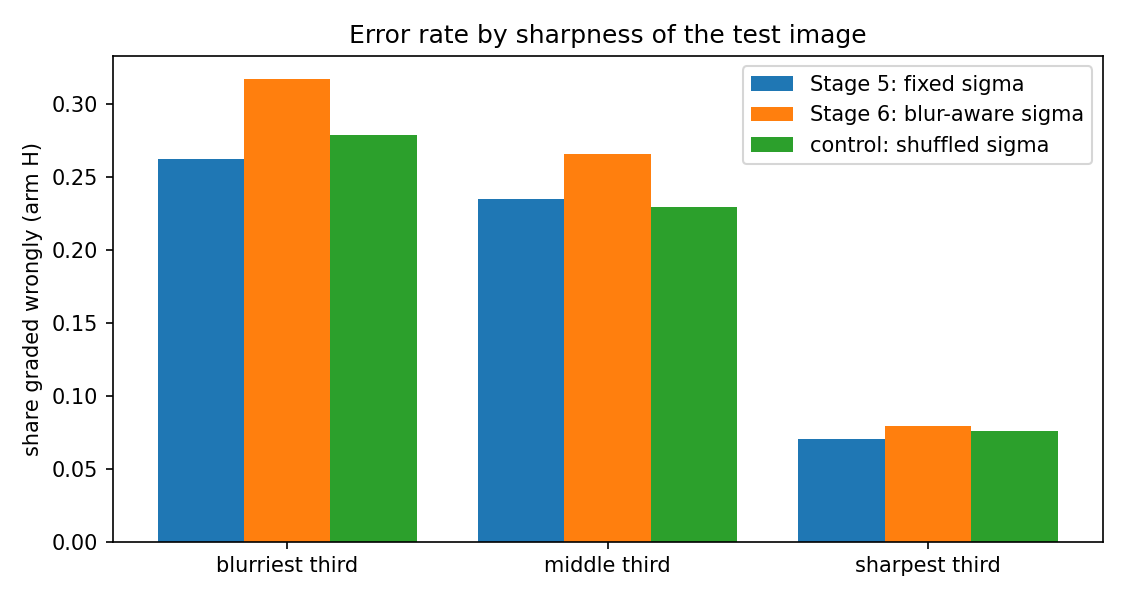

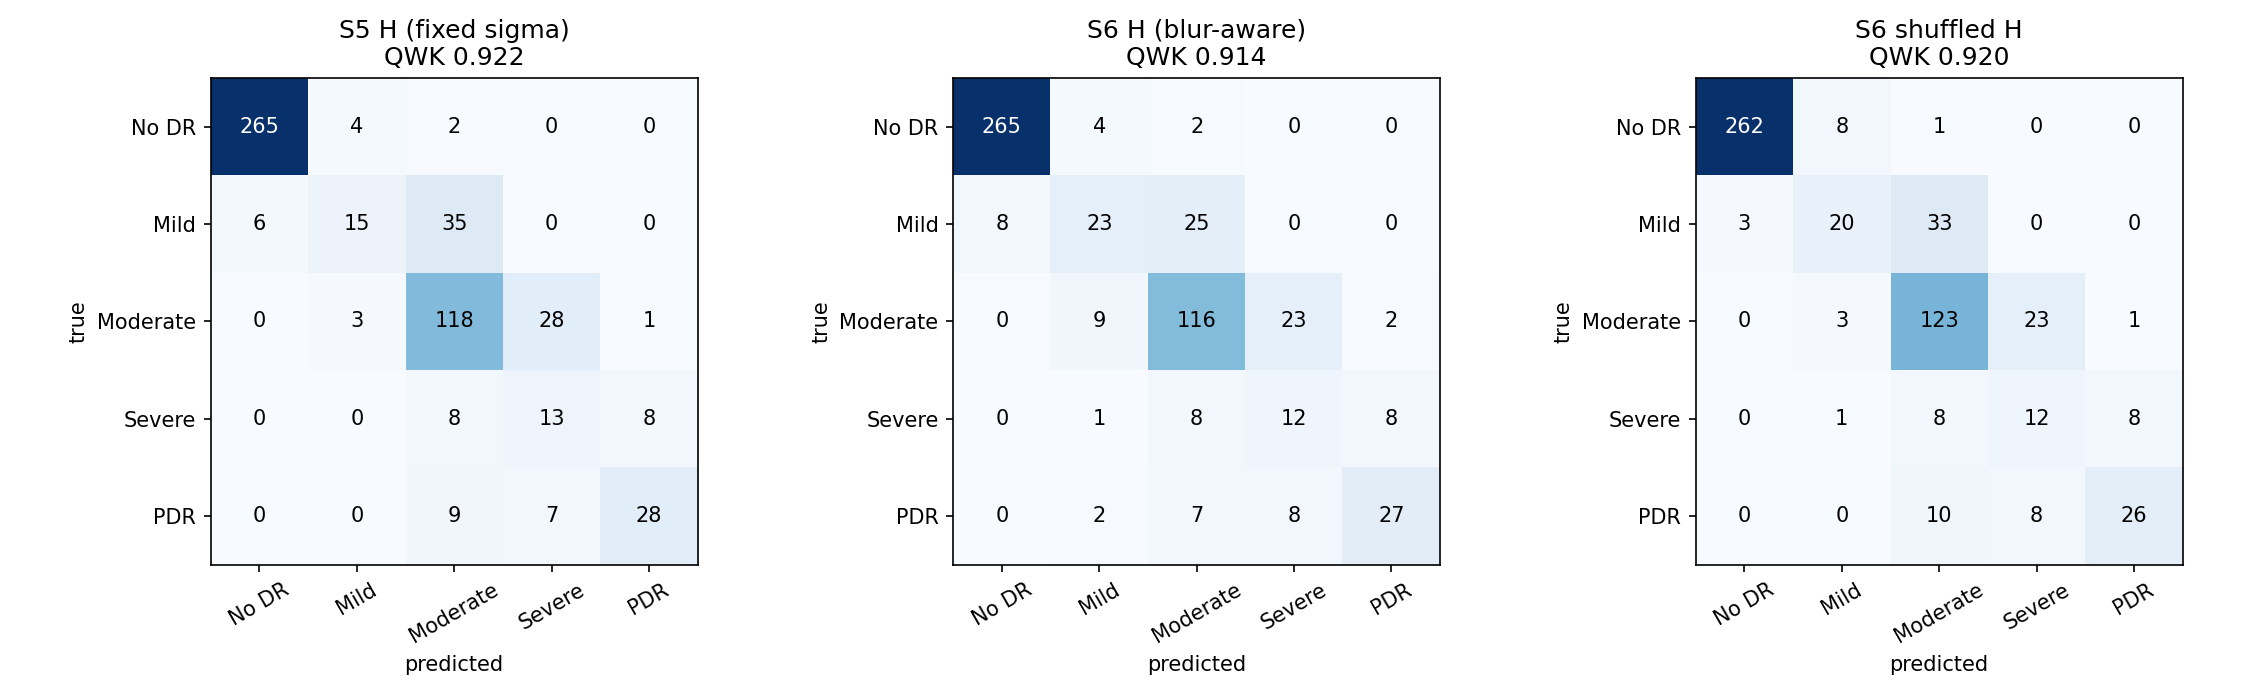

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4))
width = 0.27
for k, (group, label) in enumerate([("S5", "Stage 5: fixed sigma"), ("S6", "Stage 6: blur-aware sigma"), ("S6 shuffled", "control: shuffled sigma")]):
    if (group, "H") in summary_t.index:
        ax.bar(np.arange(3) + (k - 1) * width, summary_t.loc[(group, "H")].values, width, label=label)
ax.set_xticks(range(3)); ax.set_xticklabels(TERCILE_NAMES); ax.set_ylabel("share graded wrongly (arm H)")
ax.set_title("Error rate by sharpness of the test image"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "error_by_sharpness.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, key) in zip(axes, [("S5 H (fixed sigma)", ("S5", f"soft_s{s0}")), ("S6 H (blur-aware)", ("S6", f"blur_s{s0}")),
                                   ("S6 shuffled H", ("S6 shuffled", f"blur_shuffled_s{s0}"))]):
    y, pred, _ = decisions[(key[0], key[1], "ensemble", "H")]
    cm = confusion_matrix(y, pred, labels=list(range(NUM_CLASSES)))
    ax.imshow(cm, cmap="Blues")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30); ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_title(f"{title}\nQWK {qwk(y, pred):.3f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=150); plt.show()

## 12. Files

Written to `dr-grading/stage6/` in this kernel's output: `results_per_seed.csv`, `results_mean_over_seeds.csv`, `error_by_sharpness.csv`, `paired_bootstrap.csv`, `prediction_check.csv`, `figures/`, and `runs/<name>/` per run. Copy the CSVs and figures into `experiments/08_blur_aware/results/` and write `experiments/08_blur_aware/results.md`.